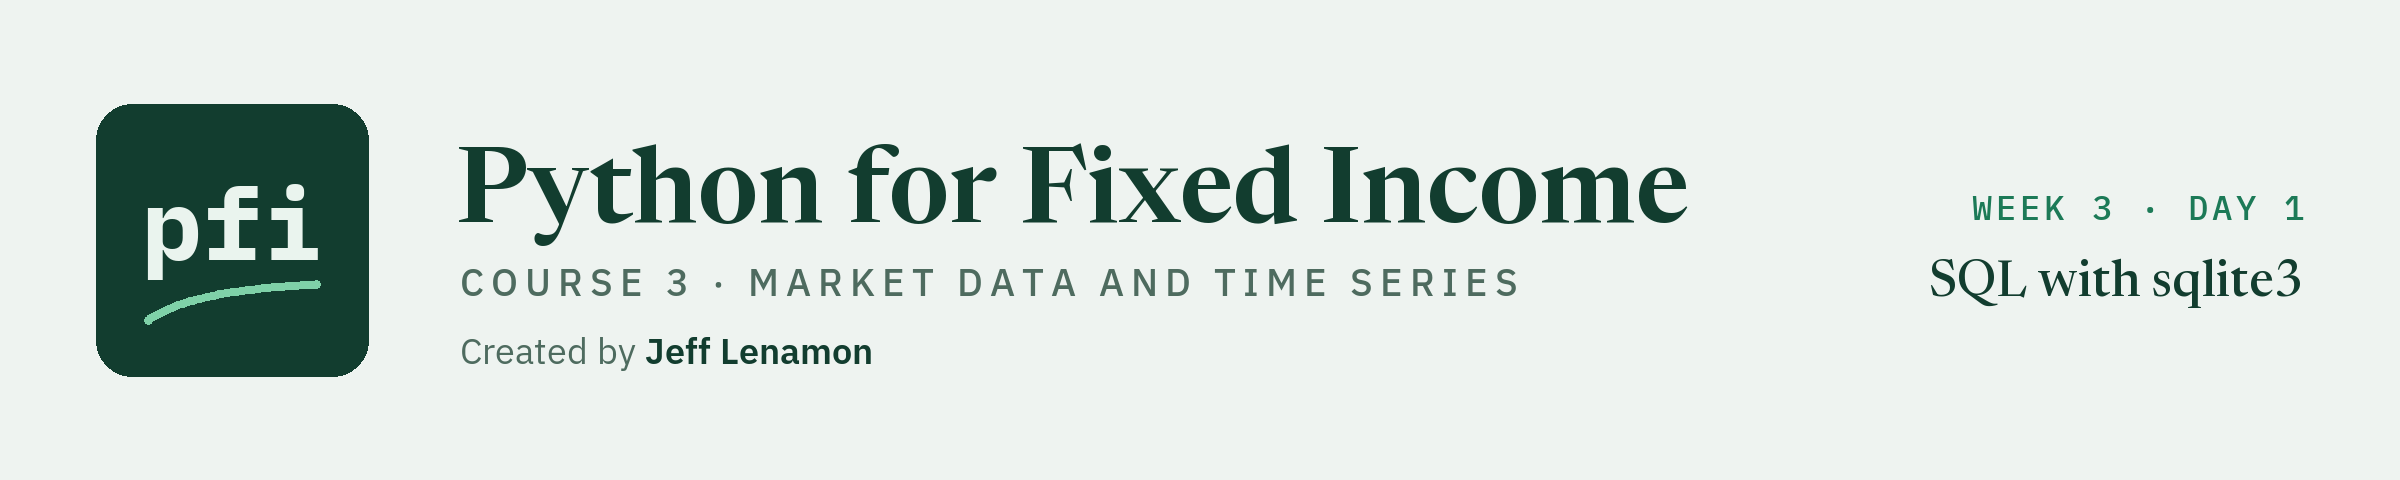

# SQL with sqlite3

Week 3, Day 1. Your book in a database: SQL with Python's built-in sqlite3. Every query sits beside the pandas you already know, and an assert proves the two return the same rows.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course3_market_data/week3/day1/11_sql_with_sqlite3.ipynb)

Week 2 ended with `summary_table` and three years of the curve and the synthetic spreads. Week 3 turns to the book and to the tools around it: SQL today and tomorrow, an AI assistant on day 13, and the daily market snapshot on day 14.

Courses 1 and 2 kept the course's synthetic book in CSV files and answered every question with pandas. On many desks the same kind of data sits in a **database**, and the language for asking a database a question is **SQL**. Today the book goes into a database file: the 200 holdings as of 2026-09-30, the issuers, the rating scale, the benchmark, the trade blotter, the Treasury curve, and the synthetic spreads.

One rule runs through the day: **every query is set beside its pandas version, and an assert proves they return the same rows.** A query that runs is not yet a query that is right.

Today you will:

1. See what SQL is for, and why you will read so much of it.
2. Make a database in one file with Python's own `sqlite3`.
3. Write `load_tables`, which writes CSV files to tables and checks the row counts.
4. Write `run_query` and `assert_same_rows`, and ask `SELECT`, `WHERE`, `ORDER BY`, and `LIMIT` questions, each beside pandas.
5. Pass values with `?` parameters, and see what goes wrong without them.
6. Group with `GROUP BY`, `COUNT`, `SUM`, `AVG`, and `HAVING`.
7. Compute the market-value weighted OAS in SQL and check it against your `bondmath.weighted_average`.

Today has no live cell: everything comes from the course's files, so no FRED key is needed.

The setup cell is the usual one. Today it copies the book's files (holdings, issuers, ratings, benchmark, trades) as well as the market files the tests read.

Q. Set up today's work folder and copy today's data files into it.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course3_market_data/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

9 packages checked, all present


In [2]:
# today's setup: modules, the course data, a fresh work folder, and the constants the live cells use
import importlib
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import pandas as pd

# the course's chart style, set once here so every chart in the notebook looks the same
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),          # width and height of a chart, in inches
    "figure.dpi": 110,                 # sharpness on screen
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    # the course greens, then a grey, for the first four lines or bars of a chart
    "axes.prop_cycle": plt.cycler(color=["#123d2f", "#1c7a57", "#7fd1a8", "#8c8c8c"]),
    "axes.grid": True,                 # light gridlines, as in an Excel chart
    "grid.color": "#dddddd",
    "axes.spines.top": False,          # no box line above or to the right of the plot
    "axes.spines.right": False,
})

# three packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("pytest", "pytest"), ("requests", "requests"), ("dotenv", "python-dotenv")]:
    try:
        importlib.import_module(module_name)
    except ImportError:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.") from None
import pytest
import requests

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()
data_folder = RAW_DATA if on_github else str(local_data) + os.sep

# 2. your own key file: in your my_bondmath folder, outside every repository. Its path is never printed.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"

# 3. the two constants of the live cells
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen unless you set this to True, on your own machine only
SHOW_LICENSED_VALUES = False

# 4. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course3_11_"))
os.chdir(work)

# 5. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv", "course3_fred_format_dgs10.json", "course3_fred_format_dgs2.json", "course3_excel_reference.csv", "holdings.csv", "ratings.csv", "issuers.csv", "benchmark.csv", "trade_blotter.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES) or 'none'}")
print(f"pytest {pytest.__version__}, requests {requests.__version__}")

Work folder: pfi_course3_11_3b6db0ir, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv, course3_fred_format_dgs10.json, course3_fred_format_dgs2.json, course3_excel_reference.csv, holdings.csv, ratings.csv, issuers.csv, benchmark.csv, trade_blotter.csv
pytest 9.1.1, requests 2.34.2


Q. Write `bondmath.py`, the reference copy of the module you finished in Course 2.

It is written into the work folder so that every notebook runs, in Colab too, whether or not you took Course 2. To use your own copy instead, run this line in a new cell after the next one:

```python
shutil.copy(Path.home() / "projects" / "my_bondmath" / "bondmath.py", work)
```

The saved outputs of this notebook always come from the reference copy.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `marketdata.py` and `test_marketdata.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table

Writing marketdata.py


In [5]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)


def ten_year_and_2s10s() -> dict[str, pd.Series]:
    """The 10 Yr in percent and 2s10s in bp, (10 Yr - 2 Yr) x 100 as the Excel sheet computes it."""
    curve = read_treasury()
    return {"10y": curve["10 Yr"], "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100}


def test_zscore_matches_excel_standardize():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        z = md.rolling_zscore(series, window=252)
        for day, row in reference.iterrows():
            assert z.loc[day] == pytest.approx(row[f"zscore252_{name}"], abs=1e-9), (name, day)


def test_zscore_nan_when_flat():
    dates = pd.bdate_range("2026-09-01", periods=6)
    stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
    z = md.rolling_zscore(stale, window=3)
    # windows ending on the third and fourth rows are flat: no z-score
    assert z.iloc[:4].isna().all()
    assert z.iloc[4:].notna().all()


def test_percentile_matches_excel_countif():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        rank = md.rolling_percentile_rank(series, window=252)
        for day, row in reference.iterrows():
            # Excel: =COUNTIF(window,"<="&x)/COUNT(window)*100, a ratio of whole numbers
            assert rank.loc[day] == pytest.approx(row[f"pctrank252_{name}"], abs=1e-12), (name, day)


def test_percentile_ties_count_as_at_or_below():
    dates = pd.bdate_range("2026-09-01", periods=4)
    values = pd.Series([7.0, 9.0, 7.0, 7.0], index=dates)
    rank = md.rolling_percentile_rank(values, window=4)
    # three of the four values are at or below 7: 75 percent
    assert rank.iloc[-1] == pytest.approx(75.0, abs=1e-12)
    # two slopes of 32 bp with binary noise of opposite sign are still a tie: all three at or below
    noisy = pd.Series([(4.12 - 3.80) * 100, 31.0, (4.13 - 3.81) * 100], index=dates[:3])
    assert noisy.iloc[0] > 32 > noisy.iloc[2]
    assert md.rolling_percentile_rank(noisy, window=3).iloc[-1] == pytest.approx(100.0, abs=1e-12)


def test_zscore_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_zscore(s, window=252), series, CUT_DATES)


def test_percentile_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_percentile_rank(s, window=252), series, CUT_DATES)


def test_slope_sign():
    curve = pd.DataFrame({"2 Yr": [4.88, 5.10], "10 Yr": [5.29, 5.00]}, index=pd.to_datetime(["2026-09-30", "2026-10-01"]))
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # positive when the longer yield is higher, negative when it is lower
    assert slope.iloc[0] == pytest.approx(41.0, abs=1e-9)
    assert slope.iloc[1] == pytest.approx(-10.0, abs=1e-9)


def test_butterfly_hand_value():
    curve = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
    # (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp
    assert md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(1.0, abs=1e-9)


def test_butterfly_matches_excel_reference():
    reference = read_reference()
    curve = read_treasury().loc[reference.index]
    fly = md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # Excel: =(2*C_t-B_t-D_t)*100 and =(D_t-B_t)*100
    assert ((fly - reference["fly_2s5s10s_bp"]).abs() <= 1e-9).all()
    assert ((slope - reference["slope_2s10s_bp"]).abs() <= 1e-9).all()


def test_fly_weights_neutral():
    # DV01s per 100 of face per bp of par bonds at about 2, 5, and 10 years
    dv01_short, dv01_belly, dv01_long = 0.0186, 0.0436, 0.0778
    w_short, w_belly, w_long = md.fly_weights(dv01_short, dv01_belly, dv01_long)
    assert w_belly == 1.0
    # belly on one side, both wings on the other: the DV01s net to zero, half on each wing
    assert w_belly * dv01_belly - w_short * dv01_short - w_long * dv01_long == pytest.approx(0.0, abs=1e-15)
    assert w_short * dv01_short == pytest.approx(w_long * dv01_long, abs=1e-15)


def test_fly_weights_reject_nonpositive():
    with pytest.raises(ValueError):
        md.fly_weights(0.0186, 0.0, 0.0778)
    with pytest.raises(ValueError):
        md.fly_weights(-0.0186, 0.0436, 0.0778)


def ten_year_frame() -> tuple[pd.DataFrame, dict[str, str]]:
    """The 10 Yr in percent and 2s10s in bp side by side, with their units."""
    curve = read_treasury()
    data = pd.DataFrame({"10 Yr": curve["10 Yr"], "2s10s": md.slope_bp(curve, "2 Yr", "10 Yr")})
    return data, {"10 Yr": "pct", "2s10s": "bp"}


def test_summary_table_known_date():
    data, units = ten_year_frame()
    reference = read_reference().loc["2026-10-02"]
    table = md.summary_table(data, "2026-10-02", units)
    ten, slope = table.loc["10 Yr"], table.loc["2s10s"]
    assert ten["unit"] == "pct" and slope["unit"] == "bp"
    assert ten["level"] == 5.28
    assert ten["chg_1d_bp"] == pytest.approx(reference["chg_10y_bp"], abs=1e-9)
    assert ten["chg_1m_bp"] == pytest.approx(reference["chg1m_10y_bp"], abs=1e-9)
    # one week back from Friday 2026-10-02 is Friday 2026-09-25
    expected_week = (data.loc["2026-10-02", "10 Yr"] - data.loc["2026-09-25", "10 Yr"]) * 100
    assert ten["chg_1w_bp"] == pytest.approx(expected_week, abs=1e-9)
    assert ten["zscore"] == pytest.approx(reference["zscore252_10y"], abs=1e-9)
    assert ten["pct_rank"] == pytest.approx(reference["pctrank252_10y"], abs=1e-12)
    assert slope["level"] == pytest.approx(reference["slope_2s10s_bp"], abs=1e-9)
    assert slope["zscore"] == pytest.approx(reference["zscore252_2s10s"], abs=1e-9)
    assert slope["pct_rank"] == pytest.approx(reference["pctrank252_2s10s"], abs=1e-12)


def test_summary_table_no_lookahead():
    data, units = ten_year_frame()
    for cut in CUT_DATES:
        # the table from the whole file equals the table from the file cut at the as-of date
        full = md.summary_table(data, cut, units)
        cut_only = md.summary_table(data.loc[:cut], cut, units)
        pd.testing.assert_frame_equal(full, cut_only, check_exact=True)

Writing test_marketdata.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata as md
# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(bondmath)
importlib.reload(md)
# the functions defined in each module itself, not the ones it imports
def own_functions(module):
    return [name for name, obj in vars(module).items() if callable(obj) and getattr(obj, "__module__", "") == module.__name__]

print(f"bondmath (the Course 2 reference): {len(own_functions(bondmath))} functions")
print(f"marketdata functions: {own_functions(md)}")

bondmath (the Course 2 reference): 25 functions
marketdata functions: ['get_secret', 'fred_params', 'parse_fred_observations', 'fred_series', '_check_index', 'missing_weekdays', 'align', 'stale_runs', '_check_series', 'last_per_period', 'value_as_of', 'write_cache', 'read_cache', 'cached_fred_series', 'change_bp', 'return_pct', 'change_since_bp', 'rolling_vol_bp', 'rolling_zscore', 'rolling_percentile_rank', 'slope_bp', 'butterfly_bp', 'fly_weights', 'summary_table']


* `marketdata.py` holds the functions of weeks 1 and 2. Today adds three more.

## 11.1 Why SQL, and Why Assistants Write So Much of It

A relational database keeps data in **tables**: named columns, one row per record, exactly the shape of a CSV file or a DataFrame. SQL (Structured Query Language) is how a program asks it for rows. You describe the result you want, which columns, which rows, grouped how, and the database works out how to get it.

Security masters, position records, and trade histories very often live in databases, and reports read them with SQL. AI assistants write SQL readily too: a desk question in plain English becomes a few lines of SQL, and those lines run without an error whether the answer is right or not. So this course never takes a query on trust. You will read SQL, and you will check it against pandas, which you already trust.

Most of what you know in pandas has a SQL word:

| Job | pandas (Course 1) | SQL |
| --- | --- | --- |
| A table | a DataFrame | a table |
| Pick columns | `holdings[["cusip", "oas"]]` | `SELECT cusip, oas FROM holdings` |
| Pick rows | `holdings[holdings["oas"] > 200]` | `WHERE oas > 200` |
| Sort | `.sort_values("oas", ascending=False)` | `ORDER BY oas DESC` |
| The first n rows | `.head(5)` | `LIMIT 5` |
| Group and total | `.groupby("sector").agg(...)` | `GROUP BY sector` with `COUNT`, `SUM`, `AVG` |
| Keep some groups | a filter after the `groupby` | `HAVING` |
| Join two tables | `pd.merge(...)` | `JOIN` (tomorrow, day 12) |

## 11.2 `sqlite3`: a Database in One File

Most databases run as a server that you log in to. **SQLite** is different: the whole database is one file, and the program reads and writes it directly. There is nothing to install and no password, and Python ships with it as the `sqlite3` module.

> **Story: the database you already have.** SQLite's own documentation says "A database in SQLite is a single disk file" and that the file format is cross-platform, so a database made on one machine can be copied to another. On a separate page it says "SQLite is likely used more than all other database engines combined", and that it is "used extensively in every smartphone". Sources: SQLite, "Single-file Cross-platform Database", https://www.sqlite.org/onefile.html, and "Most Widely Deployed and Used Database Engine", https://www.sqlite.org/mostdeployed.html (both read 2026-10-04).

Q. Which SQLite does this Python carry?

In [7]:
import sqlite3

# the module ships with Python; sqlite_version is the database engine inside it
print(f"SQLite {sqlite3.sqlite_version}, built into this Python")

SQLite 3.50.4, built into this Python


Q. Connect to a new database file, `course3.db`, in the work folder, and ask it one small question.

In [8]:
from contextlib import closing

db_path = work / "course3.db"

# connect opens the file, and creates it if it is not there; closing() closes it at the end of the block
with closing(sqlite3.connect(db_path)) as connection:
    # one row, two columns: the same division with a whole number and with a decimal
    whole, decimal = connection.execute("SELECT 7 / 2, 7 / 2.0").fetchone()

print(f"{db_path.name} exists: {db_path.exists()}")
print(f"7 / 2 = {whole}, 7 / 2.0 = {decimal}")

course3.db exists: True
7 / 2 = 3, 7 / 2.0 = 3.5


* The file exists as soon as you connect. It lives in the work folder, never in the course repo.
* `7 / 2` gave `3`: **SQLite divides two whole numbers as whole numbers** and drops the remainder. `7 / 2.0` gave `3.5`. Remember it when you divide two counts: write `* 1.0` on one of them. A market value in dollars with cents is a decimal number, so today's weighted average is safe.
* `closing()` matters: a `sqlite3` connection's own `with` block commits or rolls back, but it does not close the file. `closing` from the standard library's `contextlib` closes it.

## 11.3 `load_tables`

First the data goes in. `pandas` writes a DataFrame to a database table with `to_sql`, so loading a CSV file is two lines. `load_tables` does it for several files at once, and then reads each table's row count back from the database and checks it against the CSV, a control total of the kind Course 1 taught.

As always, the docstring first. Read it, then run the cell. The two imports at the top are new for the module; in your own file you may move them up to the other imports.

Q. Add `load_tables` to `marketdata.py`.

In [9]:
%%writefile -a marketdata.py


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts

Appending to marketdata.py


* A **table name cannot be a `?` parameter** (section 11.5), so it has to be pasted into the SQL text. That is safe only for a plain name, so the function refuses any name that is not letters, digits, and underscores. Values never go in this way.
* `if_exists="replace"` means loading again replaces the table instead of adding the rows a second time.

Q. Reload the module so the new function is picked up.

In [10]:
importlib.reload(md)
print(f"load_tables is in marketdata: {hasattr(md, 'load_tables')}")

load_tables is in marketdata: True


Q. The Treasury file is wide: one column per tenor. A database table is usually long: one row per date and tenor. Melt it into `date`, `tenor`, `years`, `yield_pct`, and drop the tenors that had not started yet.

In [11]:
treasury_wide = pd.read_csv("treasury_par_yields.csv", float_precision="round_trip")

# melt turns the tenor columns into rows: one row per date and tenor
treasury_long = treasury_wide.melt(id_vars="date", var_name="tenor", value_name="yield_pct")
# a tenor that had not started yet is empty: drop the row rather than store a missing yield
treasury_long = treasury_long.dropna(subset=["yield_pct"])

# years from the label: "3 Mo" and "1.5 Month" are months over 12, "10 Yr" is 10
treasury_long["years"] = [float(label.split()[0]) / 12 if "Mo" in label else float(label.split()[0])
                          for label in treasury_long["tenor"]]
treasury_long = treasury_long[["date", "tenor", "years", "yield_pct"]]
treasury_long.to_csv("treasury_long.csv", index=False)

cells = len(treasury_wide) * (treasury_wide.shape[1] - 1)
print(f"{len(treasury_wide):,} dates x {treasury_wide.shape[1] - 1} tenors = {cells:,} cells; "
      f"{len(treasury_long):,} hold a yield in percent")

2,940 dates x 14 tenors = 41,160 cells; 35,728 hold a yield in percent


* 41,160 cells, 35,728 rows with a yield: the other 5,432 are tenors before their first date, which the long table simply leaves out.
* `melt` turns columns into rows. The 14 tenor columns became one `tenor` column and one `yield_pct` column, so each date now has up to 14 short rows instead of one wide row.
* The `[ ... for label in ... ]` line is a **list comprehension**: a loop written on one line that builds a list. Here it turns each label, such as `"3 Mo"`, into a number of years.

Q. Draw how many yields each tenor has in the long table, against the 2,940 dates in the wide file.

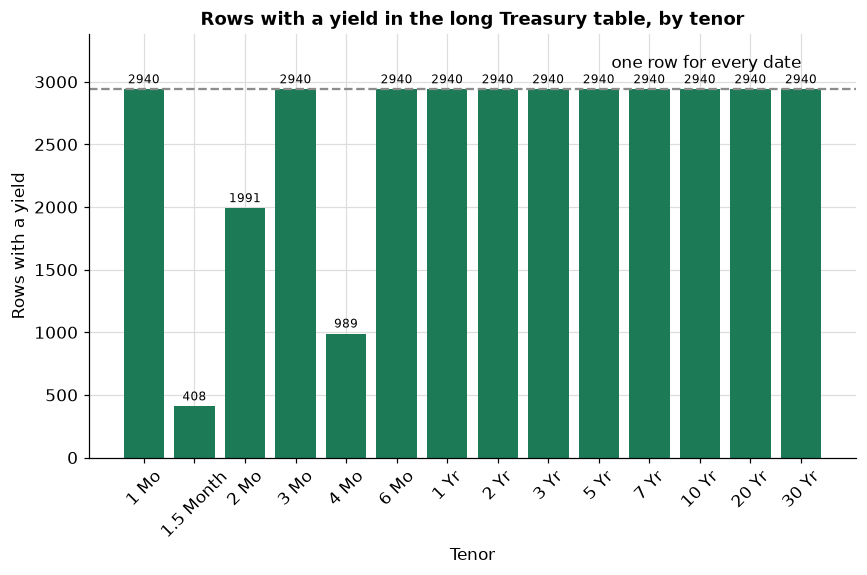

In [12]:
# rows per tenor, short tenors first; a tenor that started late has fewer rows than there are dates
per_tenor = treasury_long.groupby(["years", "tenor"]).size().reset_index(name="yields").sort_values("years")
fig, ax = plt.subplots()
bars = ax.bar(per_tenor["tenor"], per_tenor["yields"], color="#1c7a57")
ax.bar_label(bars, fontsize=8, padding=2)
# the dashed line is one row for every date in the wide file
ax.axhline(len(treasury_wide), linestyle="--", color="#8c8c8c")
ax.annotate("one row for every date", (len(per_tenor) - 1, len(treasury_wide)), textcoords="offset points",
            xytext=(0, 14), ha="right")
ax.set_axisbelow(True)
ax.set_ylim(0, len(treasury_wide) * 1.15)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Tenor")
ax.set_ylabel("Rows with a yield")
ax.set_title("Rows with a yield in the long Treasury table, by tenor")
plt.show()

* Most tenors reach the dashed line: a yield on every date. The 1.5 Month, 2 Mo, and 4 Mo tenors have fewer rows, because their yields start later in the file. The long table keeps only what exists, so a missing yield is a missing row, not a blank.

Q. Load seven tables into `course3.db`.

In [13]:
# table name: the CSV file it comes from
TABLES = {
    "holdings": work / "holdings.csv",
    "issuers": work / "issuers.csv",
    "ratings": work / "ratings.csv",
    "benchmark": work / "benchmark.csv",
    "trades": work / "trade_blotter.csv",
    "treasury": work / "treasury_long.csv",
    "spreads": work / "course3_synthetic_spreads.csv",
}
table_counts = md.load_tables(db_path, TABLES)
for name, count in table_counts.items():
    print(f"{name:10} {count:>7,} rows, the same as its CSV")

holdings       200 rows, the same as its CSV
issuers        150 rows, the same as its CSV
ratings         18 rows, the same as its CSV
benchmark      821 rows, the same as its CSV
trades         374 rows, the same as its CSV
treasury    35,728 rows, the same as its CSV
spreads      2,940 rows, the same as its CSV


* Seven tables, each count read back from the database and checked against its CSV inside `load_tables`: holdings 200, issuers 150, ratings 18, benchmark 821, trades 374, spreads 2,940, treasury 35,728. The spreads are synthetic, invented for this course, and are not ICE, Moody's, or any index.

Q. Is the database file text, like a CSV? Read the first 16 bytes of each.

In [14]:
# read_bytes reads a file as raw bytes, without treating it as text
print(f"course3.db:   {db_path.read_bytes()[:16]}")
print(f"holdings.csv: {Path('holdings.csv').read_bytes()[:16]}")

course3.db:   b'SQLite format 3\x00'
holdings.csv: b'as_of_date,cusip'


* The CSV starts with its header, readable text. The database starts with `SQLite format 3` and a zero byte, and the rest of it is not text at all. SQLite's file format documentation says: "Every valid SQLite database file begins with the following 16 bytes" and names this string (https://www.sqlite.org/fileformat.html, read 2026-10-04).
* **A database file is binary.** Git can store it, but cannot show what changed inside it line by line, and every reload rewrites it. It is also rebuilt from the CSV files by one call to `load_tables`. So the CSV files and the code are the record, and `*.db` goes in `.gitignore`, as it has since day 1. The Git section checks it.

## 11.4 `SELECT`, `WHERE`, `ORDER BY`, `LIMIT`, Each Beside pandas

Two more functions first. `run_query` sends one query and returns a DataFrame. `assert_same_rows` is the day's rule as code: it checks that a SQL result and a pandas result hold the same rows, whatever their order.

Q. Add `run_query`. Read its docstring first.

In [15]:
%%writefile -a marketdata.py


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)

Appending to marketdata.py


* `pd.read_sql_query` runs the SQL and builds the DataFrame. `params` carries the values for the `?` marks.
* Asking `sqlite3` to connect to a file that is not there would quietly create an empty database, and every query would then fail with "no such table". The function stops first with a clearer message, and names only the file, never its folder.

Q. Add `assert_same_rows`.

In [16]:
%%writefile -a marketdata.py


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)

Appending to marketdata.py


* Rows are sorted by the keys you name and the index is reset, so the order each side happens to come back in does not matter.
* Text and whole numbers must be equal exactly. Decimals may differ by the tiniest amount, because SQLite and pandas may add the same numbers in a different order: `rtol=1e-12`, `atol=1e-9`, the course's tolerance for SQL against pandas.

Q. Reload, and list the tables the database holds. `sqlite_master` is SQLite's own table of contents.

In [17]:
importlib.reload(md)

# ? is a placeholder; the value "table" goes in through params (section 11.5 says why)
md.run_query(db_path, "SELECT name FROM sqlite_master WHERE type = ? ORDER BY name", ("table",))

,name
0,benchmark
1,holdings
2,issuers
3,ratings
4,spreads
5,trades
6,treasury


Q. `SELECT` and `FROM`: four columns of every bond. Then the same in pandas, and the assert.

In [18]:
holdings = pd.read_csv("holdings.csv")

# SELECT names the columns, FROM names the table
from_sql = md.run_query(db_path, "SELECT cusip, issuer, sector, oas FROM holdings")
from_pandas = holdings[["cusip", "issuer", "sector", "oas"]]

# the day's rule: the same rows, checked by an assert
md.assert_same_rows(from_sql, from_pandas, sort_by=["cusip"])
print(f"{len(from_sql)} rows from SQL, {len(from_pandas)} from pandas: the same rows")
from_sql.head(3)

200 rows from SQL, 200 from pandas: the same rows


,cusip,issuer,sector,oas
0,99080CAE8,Bezane Finance,Financials,147
1,99049XAE2,Bezamyth Machinery,Industrials,535
2,99039NAC0,Bezoquil Freight,Transportation,153


* `SELECT *` would give every column. SQL keywords are written in capitals by convention only; SQLite reads `select` just as well.
* `holdings[["cusip", "issuer", "sector", "oas"]]` picks columns by name in pandas, the twin of `SELECT`. `.head(3)` shows the first three rows.
* An `assert` is a check that stays silent when it passes and stops the cell with an error when it fails. `assert_same_rows` is the day's check in one line: no error means the two results hold the same rows.

Q. `WHERE`: the Energy bonds with an OAS above 200 bp.

In [19]:
# each ? is filled, in order, from the tuple of values
from_sql = md.run_query(db_path, "SELECT cusip, issuer, oas FROM holdings WHERE sector = ? AND oas > ?",
                        ("Energy", 200))

# pandas: a mask of True and False, the same two conditions joined by &
mask = (holdings["sector"] == "Energy") & (holdings["oas"] > 200)
from_pandas = holdings.loc[mask, ["cusip", "issuer", "oas"]]

md.assert_same_rows(from_sql, from_pandas, sort_by=["cusip"])
from_sql

,cusip,issuer,oas
0,99145PAA0,Praximer Energy,468
1,99074WAB8,Wyxundra Energy,532
2,99074WAD4,Wyxundra Energy,332


* 3 bonds. SQL writes `AND` and `OR` where pandas writes `&` and `|`, and tests equality with a single `=`.
* The pandas `mask` is a column of True and False, one for each bond. `holdings.loc[mask, [...]]` keeps the rows where it is True and the columns named. `WHERE` does the same job in one clause.

Q. Draw what `WHERE` keeps: every Energy bond by OAS, with the cut at 200 bp.

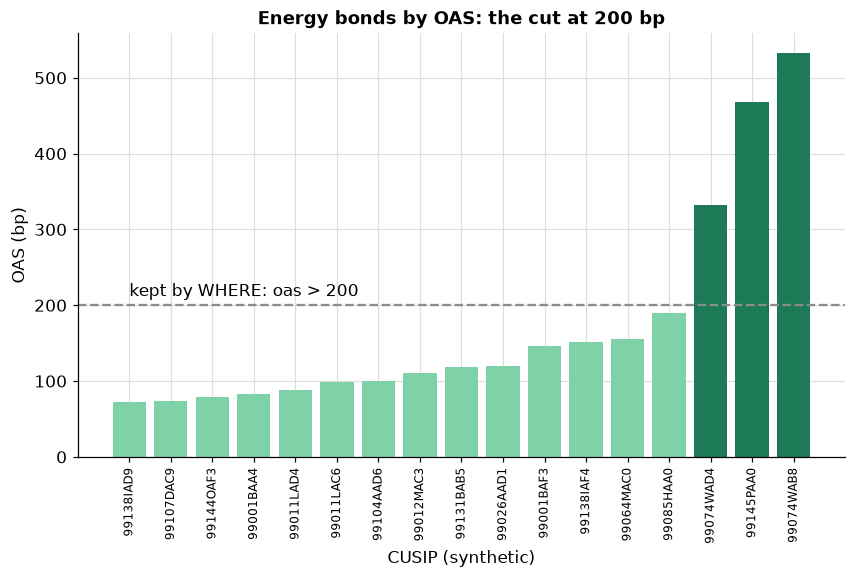

In [20]:
# every bond of the sector, narrowest on the left; the dashed line is the WHERE condition
sector_oas = md.run_query(db_path, "SELECT cusip, oas FROM holdings WHERE sector = ? ORDER BY oas", ("Energy",))
kept = sector_oas["oas"] > 200
# the bars above the line are exactly the rows the WHERE query returned
assert kept.sum() == len(from_sql)

fig, ax = plt.subplots()
ax.bar(sector_oas["cusip"], sector_oas["oas"], color=["#1c7a57" if keep else "#7fd1a8" for keep in kept])
ax.axhline(200, linestyle="--", color="#8c8c8c")
ax.annotate("kept by WHERE: oas > 200", (0, 200), textcoords="offset points", xytext=(0, 6))
ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.set_xlabel("CUSIP (synthetic)")
ax.set_ylabel("OAS (bp)")
ax.set_title("Energy bonds by OAS: the cut at 200 bp")
plt.show()

* The dark bars sit above the dashed line: those 3 are the rows the query returned. The light bars are the Energy bonds the `WHERE` dropped.

Q. `ORDER BY` and `LIMIT`: the five largest positions by market value, in dollars.

In [21]:
from_sql = md.run_query(db_path, "SELECT cusip, issuer, market_value FROM holdings ORDER BY market_value DESC LIMIT ?",
                        (5,))
from_pandas = holdings.sort_values("market_value", ascending=False).head(5)[["cusip", "issuer", "market_value"]]

md.assert_same_rows(from_sql, from_pandas, sort_by=["cusip"])
# assert_same_rows ignores order on purpose; here the order is the answer, so check it too
assert from_sql["cusip"].tolist() == from_pandas["cusip"].tolist(), "the order differs"

# a styled table: .style formats the table for the eye, .format sets the digits, .highlight_max shades the largest value
(from_sql.style
    .hide(axis="index")
    .format({"market_value": "{:,.0f}"})
    .highlight_max(subset=["market_value"], color="#bfe8d2")
    .set_caption("The five largest positions, market value in dollars"))

cusip,issuer,market_value
99080CAE8,Bezane Finance,"5,435,500"
99021VAC2,Feskundra Systems,"5,422,700"
99076YAC0,Lorvebran Paper,"5,287,462"
99129ZAB6,Zarizal Industrial,"5,253,950"
99144OAF3,Lorvellix Energy,"5,241,650"


* The largest position is Bezane Finance, 5,435,500 dollars of market value.
* **Without `ORDER BY`, a database promises no order**, so `LIMIT 5` alone gives five rows, not the first five of anything. And when two rows tie on the sort column, add a second column to the `ORDER BY` so the cut is always the same (exercise 2).
* This is a **styled table**. `.style` dresses a DataFrame the way you would dress a range in Excel. `.format` is Format Cells: the thousands commas and the number of decimals. `.highlight_max` is a Conditional Formatting rule, Top/Bottom Rules, the Top 10 Items rule set to 1. `.set_caption` is the title above the table. The numbers underneath do not change, only how they look.

Q. Draw the same five positions, largest at the top.

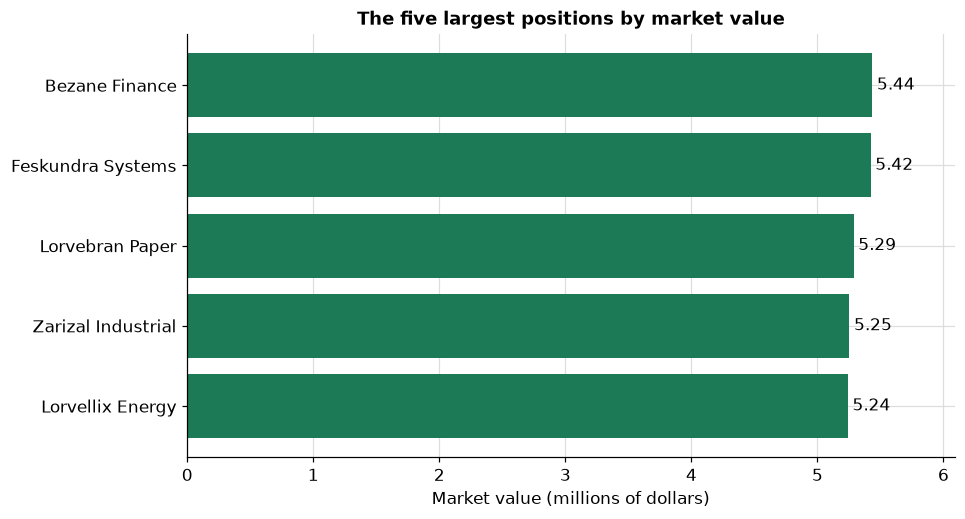

In [22]:
# horizontal bars, in the order the query returned them
fig, ax = plt.subplots()
bars = ax.barh(from_sql["issuer"], from_sql["market_value"] / 1e6, color="#1c7a57")
# the first row is the largest: put it at the top
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_axisbelow(True)
ax.margins(x=0.12)
ax.set_xlabel("Market value (millions of dollars)")
ax.set_title("The five largest positions by market value")
plt.show()

* Read the bars from the top: `ORDER BY market_value DESC` put the largest first, and `LIMIT 5` cut the list after five. Take either clause away and the picture changes.

Q. Dates: SQLite has no date type, so the course stores dates as ISO text, `YYYY-MM-DD`. Which bonds mature before 2030?

In [23]:
from_sql = md.run_query(db_path, "SELECT cusip, issuer, maturity FROM holdings WHERE maturity < ? ORDER BY maturity",
                        ("2030-01-01",))
from_pandas = holdings.loc[holdings["maturity"] < "2030-01-01", ["cusip", "issuer", "maturity"]]
md.assert_same_rows(from_sql, from_pandas, sort_by=["cusip"])

first = from_sql["maturity"].iloc[0]
print(f"{len(from_sql)} bonds mature before 2030; the first on {first}, held as {type(first).__name__}")

34 bonds mature before 2030; the first on 2027-10-02, held as str


* 34 bonds, the first maturing on 2027-10-02. ISO text sorts and compares in date order, year first, so `<` on text gives the right answer. A date written `MM/DD/YYYY` would not.
* The value comes back as text, `str`. To work with it as a date, convert it.

Q. Draw the book's maturities by year, with the 2030 cut marked.

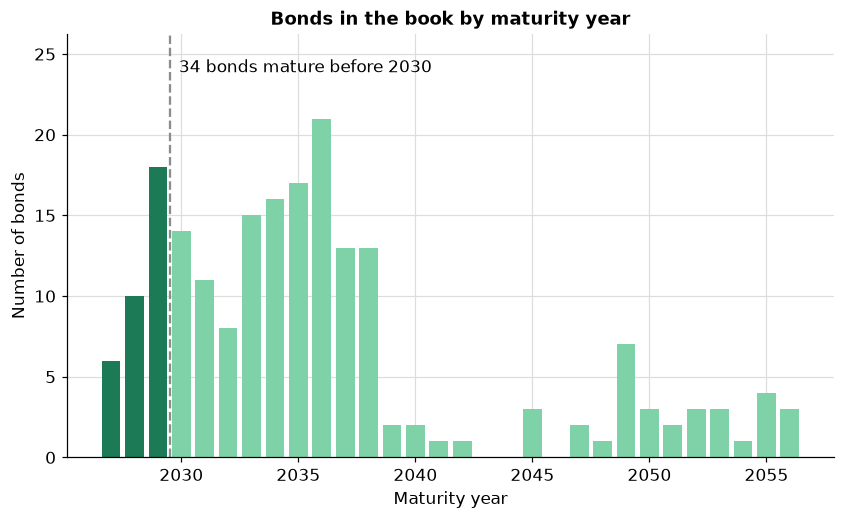

In [24]:
# the first four characters of the ISO text are the year; count the bonds maturing in each year
by_year = holdings["maturity"].str[:4].astype(int).value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(by_year.index, by_year.values, color=["#1c7a57" if year < 2030 else "#7fd1a8" for year in by_year.index])
# the cut sits between 2029 and 2030, because maturity < "2030-01-01" keeps 2029 and earlier
ax.axvline(2029.5, linestyle="--", color="#8c8c8c")
ax.set_ylim(0, by_year.max() * 1.25)
ax.annotate(f"{len(from_sql)} bonds mature before 2030", (2029.5, by_year.max() * 1.15), textcoords="offset points",
            xytext=(6, 0), ha="left", va="center")
ax.set_axisbelow(True)
ax.set_xlabel("Maturity year")
ax.set_ylabel("Number of bonds")
ax.set_title("Bonds in the book by maturity year")
plt.show()

* The dark bars left of the dashed line are the 34 bonds the query returned. Years with no bond have no bar, because the x axis is a real timeline.

Q. The 10 Yr yield from the long Treasury table for the last five market days of September 2026, read back as dates and checked against the wide file.

In [25]:
sql = "SELECT date, yield_pct FROM treasury WHERE tenor = ? AND date >= ? AND date <= ? ORDER BY date"
from_sql = md.run_query(db_path, sql, ("10 Yr", "2026-09-24", "2026-09-30"))
# text in the database, dates in pandas: convert after reading
from_sql["date"] = pd.to_datetime(from_sql["date"])

wide_rows = treasury_wide[(treasury_wide["date"] >= "2026-09-24") & (treasury_wide["date"] <= "2026-09-30")]
from_pandas = wide_rows[["date", "10 Yr"]].rename(columns={"10 Yr": "yield_pct"})
from_pandas = from_pandas.assign(date=pd.to_datetime(from_pandas["date"]))

md.assert_same_rows(from_sql, from_pandas, sort_by=["date"])
from_sql

,date,yield_pct
0,2026-09-24,5.18
1,2026-09-25,5.17
2,2026-09-28,5.24
3,2026-09-29,5.26
4,2026-09-30,5.29


* 5 market days, 2026-09-24 to 2026-09-30, ending at 5.29 percent on 2026-09-30. `pd.read_sql_query` also takes a `parse_dates=` argument; `run_query` keeps to the plain call, so the conversion is a visible step here.

## 11.5 Parameters with `?`

**Why `?`.** A value pasted into the SQL text with an f-string becomes part of the SQL itself, so a quote inside the value can break the query or change what it asks. A `?` parameter is sent to the database separately from the SQL, and is only ever read as a value.

Q. A ticker with an apostrophe in it, `O'BRN` (there is no such ticker in the book), pasted into the SQL with an f-string. This is the wrong way, shown once.

In [26]:
ticker = "O'BRN"
try:
    # the wrong way: the value pasted into the SQL text
    md.run_query(db_path, f"SELECT cusip FROM holdings WHERE ticker = '{ticker}'")
except pd.errors.DatabaseError as error:
    # the class and the message only
    print(f"{type(error).__name__}: {error}")

DatabaseError: Execution failed on sql 'SELECT cusip FROM holdings WHERE ticker = 'O'BRN'': near "BRN": syntax error


* The apostrophe in the value closed the SQL quote early, and SQLite read `BRN'` as broken SQL: `syntax error`.

Q. The same question with a parameter.

In [27]:
from_sql = md.run_query(db_path, "SELECT cusip FROM holdings WHERE ticker = ?", (ticker,))
print(f"bonds with ticker {ticker}: {len(from_sql)}")

bonds with ticker O'BRN: 0


* No error, and the right answer: none. The apostrophe is just a character of the value.

Q. Worse than an error: a value that rewrites the question. Ask for one ticker, pasted and as a parameter.

In [28]:
value = "NONE' OR '1'='1"
pasted = md.run_query(db_path, f"SELECT cusip FROM holdings WHERE ticker = '{value}'")
as_parameter = md.run_query(db_path, "SELECT cusip FROM holdings WHERE ticker = ?", (value,))
print(f"pasted into the SQL: {len(pasted)} rows; as a parameter: {len(as_parameter)} rows")

pasted into the SQL: 200 rows; as a parameter: 0 rows


* Pasted, the value turned the query into `WHERE ticker = 'NONE' OR '1'='1'`, which is true for every row: 200 bonds came back from a question about one ticker, with no error to warn you. This is called **SQL injection**. As a parameter, it is a strange ticker that matches nothing.
* The rule for the rest of the course: **values go in as `?` parameters, always.** Only a table or column name, which cannot be a parameter, is put into the text, and only after a check that it is a plain name, as `load_tables` does.

Q. Draw the two answers to the one question, "which bonds have this ticker?".

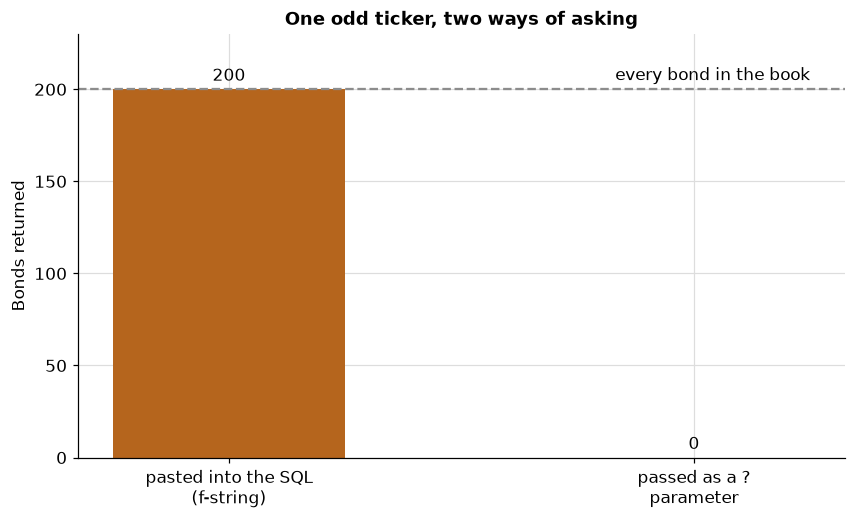

In [29]:
# the two row counts from the injection cell: len() counts the rows of each result
returned = {"pasted into the SQL\n(f-string)": len(pasted), "passed as a ?\nparameter": len(as_parameter)}
fig, ax = plt.subplots()
bars = ax.bar(list(returned), list(returned.values()), color=["#b5651d", "#1c7a57"], width=0.5)
ax.bar_label(bars, padding=3)
# the dashed line is the whole book: what a question about one ticker should never return
ax.axhline(len(holdings), linestyle="--", color="#8c8c8c")
ax.annotate("every bond in the book", (1.25, len(holdings)), textcoords="offset points", xytext=(0, 6), ha="right")
ax.set_axisbelow(True)
ax.set_ylim(0, len(holdings) * 1.15)
ax.set_ylabel("Bonds returned")
ax.set_title("One odd ticker, two ways of asking")
plt.show()

* The left bar reaches the dashed line: the pasted value rewrote the question, and the whole book came back with no error. The right bar is zero, the honest answer.

## 11.6 `GROUP BY` with `COUNT`, `SUM`, `AVG`, and `HAVING`

Q. Bonds, market value in dollars, and the simple average OAS in bp, by sector. Then Course 1's `groupby` with named aggregations, and the assert.

In [30]:
sql = """
SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value, AVG(oas) AS avg_oas
FROM holdings
GROUP BY sector
ORDER BY market_value DESC
"""
by_sector_sql = md.run_query(db_path, sql)

# each line reads: new column name = (column to use, statistic)
by_sector_pandas = holdings.groupby("sector", as_index=False).agg(
    bonds=("cusip", "count"),
    market_value=("market_value", "sum"),
    avg_oas=("oas", "mean"),
)
md.assert_same_rows(by_sector_sql, by_sector_pandas, sort_by=["sector"])

# .bar draws a bar inside each cell, in proportion to its value
(by_sector_sql.style
    .hide(axis="index")
    .format({"market_value": "{:,.0f}", "avg_oas": "{:.2f}"})
    .bar(subset=["market_value"], color="#7fd1a8")
    .set_caption("Bonds, market value (dollars), and simple average OAS (bp) by sector"))

sector,bonds,market_value,avg_oas
Materials,26,"71,701,618",182.42
Financials,26,"68,219,672",172.31
Consumer,26,"56,629,598",218.88
Telecom,21,"55,848,270",182.38
Industrials,20,"52,540,745",220.55
Transportation,20,"48,822,898",126.50
Health Care,20,"38,908,188",141.75
Energy,17,"38,830,005",171.59
Technology,12,"30,311,760",298.17
Utilities,12,"29,006,462",177.92


* 10 sectors. Materials holds the most market value, 71,701,618 dollars in 26 bonds.
* `GROUP BY sector` puts the bonds of each sector together, and `COUNT`, `SUM`, and `AVG` give one number per group. `groupby` in pandas does the same. It is Excel's pivot table with the sector in Rows.
* `COUNT(*)` counts rows; `AS` names the result's column, as the names in `.agg(...)` do. pandas returns the sectors in alphabetical order and the SQL in the order its `ORDER BY` asked for; `assert_same_rows` sorts both before comparing.
* `.bar` in the styled table draws a bar inside each cell, in proportion to its value. It is Excel's Data Bars, under Conditional Formatting.

Q. Draw market value by sector, from the same result.

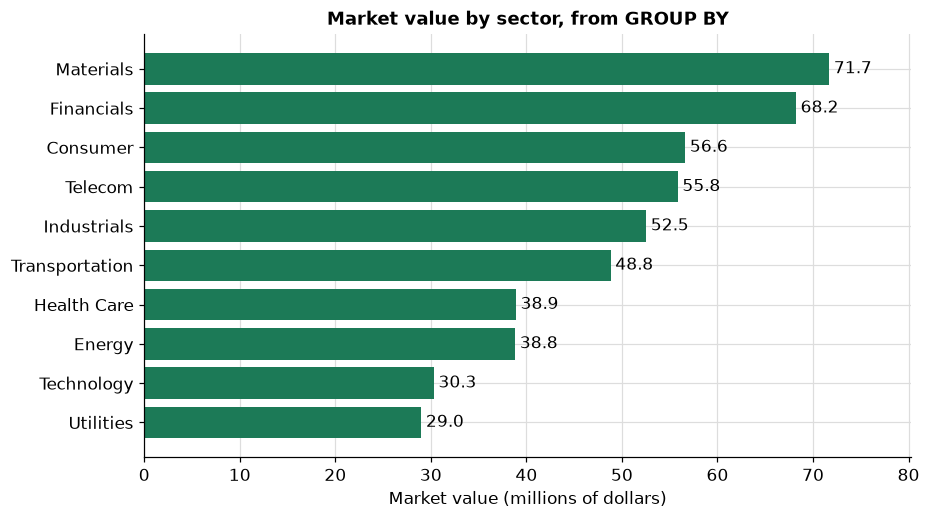

In [31]:
# smallest first, so that the largest sector is the top bar of the chart
by_value = by_sector_sql.sort_values("market_value")
fig, ax = plt.subplots()
bars = ax.barh(by_value["sector"], by_value["market_value"] / 1e6, color="#1c7a57")
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_axisbelow(True)
ax.margins(x=0.12)
ax.set_xlabel("Market value (millions of dollars)")
ax.set_title("Market value by sector, from GROUP BY")
plt.show()

* One bar per group: the 10 rows of the table, drawn. Materials is the longest bar.

Q. `HAVING`: only the sectors with at least 20 bonds.

In [32]:
sql = "SELECT sector, COUNT(*) AS bonds FROM holdings GROUP BY sector HAVING COUNT(*) >= ? ORDER BY sector"
from_sql = md.run_query(db_path, sql, (20,))

# pandas: group first, then keep the groups that pass
counts = holdings.groupby("sector", as_index=False).agg(bonds=("cusip", "count"))
from_pandas = counts[counts["bonds"] >= 20]

md.assert_same_rows(from_sql, from_pandas, sort_by=["sector"])
print(f"{len(from_sql)} of {len(counts)} sectors have at least 20 bonds")

7 of 10 sectors have at least 20 bonds


* 7 of 10: Consumer, Financials, Health Care, Industrials, Materials, Telecom, Transportation. `>=` keeps a sector with exactly 20.
* `HAVING` is a filter on the groups after `GROUP BY` has counted them. In pandas it is the line that filters the grouped table.

Q. Draw the bond count of every sector, with the `HAVING` threshold.

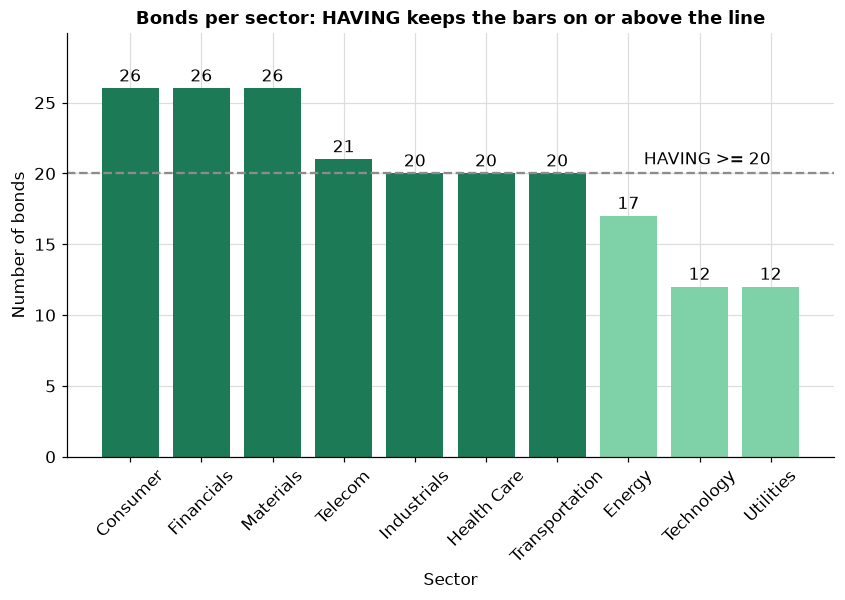

In [33]:
# `counts` is the grouped table from the cell above: one row per sector with its number of bonds
ranked = counts.sort_values("bonds", ascending=False)
passes = ranked["bonds"] >= 20
fig, ax = plt.subplots()
bars = ax.bar(ranked["sector"], ranked["bonds"], color=["#1c7a57" if keep else "#7fd1a8" for keep in passes])
ax.bar_label(bars, padding=2)
ax.axhline(20, linestyle="--", color="#8c8c8c")
ax.annotate("HAVING >= 20",(len(ranked) - 1, 20), textcoords="offset points", xytext=(0, 6), ha="right")
ax.set_axisbelow(True)
ax.set_ylim(0, ranked["bonds"].max() * 1.15)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Sector")
ax.set_ylabel("Number of bonds")
ax.set_title("Bonds per sector: HAVING keeps the bars on or above the line")
plt.show()

* The dark bars reach the dashed line or pass it: those 7 sectors are the rows `HAVING` returned. The light bars are the groups it dropped.

Q. `WHERE` and `HAVING` together: count only the bonds above 200 bp, and keep the sectors with at least 7 of them.

In [34]:
sql = """
SELECT sector, COUNT(*) AS bonds
FROM holdings
WHERE oas > ?
GROUP BY sector
HAVING COUNT(*) >= ?
ORDER BY sector
"""
from_sql = md.run_query(db_path, sql, (200, 7))

# pandas: the row filter, then the group, then the group filter
wide = holdings[holdings["oas"] > 200].groupby("sector", as_index=False).agg(bonds=("cusip", "count"))
from_pandas = wide[wide["bonds"] >= 7]

md.assert_same_rows(from_sql, from_pandas, sort_by=["sector"])
from_sql

,sector,bonds
0,Consumer,8
1,Industrials,9
2,Materials,7
3,Telecom,8


* 4 sectors: Consumer (8), Industrials (9), Materials (7), Telecom (8).

Q. Draw the two filters one after the other: the bonds above 200 bp in each sector, against the `HAVING` line.

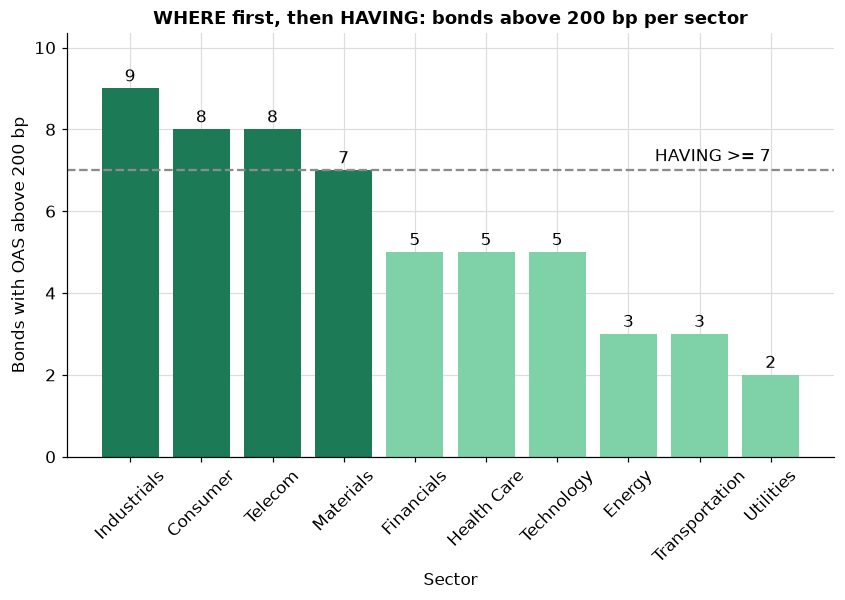

In [35]:
# `wide` is the count of bonds above 200 bp per sector, before the group filter
ranked = wide.sort_values("bonds", ascending=False)
passes = ranked["bonds"] >= 7
fig, ax = plt.subplots()
bars = ax.bar(ranked["sector"], ranked["bonds"], color=["#1c7a57" if keep else "#7fd1a8" for keep in passes])
ax.bar_label(bars, padding=2)
ax.axhline(7, linestyle="--", color="#8c8c8c")
ax.annotate("HAVING >= 7",(len(ranked) - 1, 7), textcoords="offset points", xytext=(0, 6), ha="right")
ax.set_axisbelow(True)
ax.set_ylim(0, ranked["bonds"].max() * 1.15)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Sector")
ax.set_ylabel("Bonds with OAS above 200 bp")
ax.set_title("WHERE first, then HAVING: bonds above 200 bp per sector")
plt.show()

* Each bar is shorter than in the last chart, because `WHERE` threw away the narrow bonds before the counting. `HAVING` then judged the groups on what was left.
* **`WHERE` filters rows before they are grouped; `HAVING` filters groups after.** `WHERE COUNT(*) >= 7` is an error, because a single row has no count. The clauses always come in this order: `SELECT`, `FROM`, `WHERE`, `GROUP BY`, `HAVING`, `ORDER BY`, `LIMIT`.

Q. Write today's four tests. `build_database` is a small helper that loads two tables into a test's own `tmp_path` folder.

In [36]:
%%writefile -a test_marketdata.py


def build_database(folder: Path) -> Path:
    """course3.db in `folder`, holding the holdings and ratings tables from this folder's CSV files."""
    db_path = folder / "course3.db"
    md.load_tables(db_path, {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    return db_path


def test_load_tables_counts(tmp_path):
    counts = md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    assert counts == {"holdings": 200, "ratings": 18}
    # loading again replaces the tables instead of adding rows
    assert md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv"}) == {"holdings": 200}
    with pytest.raises(ValueError):
        md.load_tables(tmp_path / "course3.db", {"holdings; DROP TABLE ratings": HERE / "holdings.csv"})


def test_run_query_params(tmp_path):
    db_path = build_database(tmp_path)
    holdings = pd.read_csv(HERE / "holdings.csv")
    result = md.run_query(db_path, "SELECT COUNT(*) AS bonds FROM holdings WHERE sector = ?", ("Energy",))
    assert result.loc[0, "bonds"] == (holdings["sector"] == "Energy").sum()
    # a value with a quote in it is just a value when it goes in as a parameter
    quoted = md.run_query(db_path, "SELECT * FROM holdings WHERE ticker = ?", ("O'BRN",))
    assert len(quoted) == 0
    with pytest.raises(FileNotFoundError):
        md.run_query(tmp_path / "missing.db", "SELECT 1")


def test_assert_same_rows_ignores_order(tmp_path):
    db_path = build_database(tmp_path)
    sql_result = md.run_query(db_path, "SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value "
                                       "FROM holdings GROUP BY sector ORDER BY market_value DESC")
    holdings = pd.read_csv(HERE / "holdings.csv")
    pandas_result = (holdings.groupby("sector", as_index=False)
                     .agg(market_value=("market_value", "sum"), bonds=("cusip", "count")))
    # different row order and column order, the same rows
    md.assert_same_rows(sql_result, pandas_result, sort_by=["sector"])


def test_assert_same_rows_catches_difference():
    left = pd.DataFrame({"sector": ["Energy", "Utilities"], "bonds": [20, 15]})
    right = pd.DataFrame({"sector": ["Utilities", "Energy"], "bonds": [15, 21]})
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, right, sort_by=["sector"])
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, left.rename(columns={"bonds": "count"}), sort_by=["sector"])

Appending to test_marketdata.py


* `test_load_tables_counts`: the counts, loading twice replaces rather than adds, and a table name with SQL in it is refused.
* `test_run_query_params`: a `?` parameter gives pandas' count, a quote in a value is just a value, and a missing file raises `FileNotFoundError`.
* `test_assert_same_rows_ignores_order` and `test_assert_same_rows_catches_difference`: the same rows in another order pass; one changed number, or a renamed column, fails.

Q. Run the tests.

In [37]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..............................................                           [100%]
46 passed in 1.27s



* `46 passed`: the 42 of weeks 1 and 2 and today's 4.

## 11.7 A Market-Value Weighted Average in SQL

`AVG(oas)` gives every bond the same say: a 250,000 dollar position counts as much as a 5 million dollar one. A desk's spread for a sector or a book is usually weighted by market value, so each dollar has the same say: the sum of OAS times market value, over the sum of market value. Course 2 wrote that as `bondmath.weighted_average`.

Q. The market-value weighted OAS by sector in SQL, beside the simple average.

In [38]:
sql = """
SELECT sector,
       SUM(oas * market_value) / SUM(market_value) AS weighted_oas,
       AVG(oas) AS avg_oas
FROM holdings
GROUP BY sector
"""
weighted_sql = md.run_query(db_path, sql)

# the same numbers from your Course 2 function, one sector at a time
rows = []
for sector, bonds in holdings.groupby("sector"):
    rows.append({"sector": sector,
                 "weighted_oas": bondmath.weighted_average(bonds["oas"].tolist(), bonds["market_value"].tolist()),
                 "avg_oas": bonds["oas"].mean()})
from_bondmath = pd.DataFrame(rows)

md.assert_same_rows(weighted_sql, from_bondmath, sort_by=["sector"])

# .background_gradient shades each cell by its value: darker green for a wider weighted OAS
(weighted_sql.style
    .hide(axis="index")
    .format({"weighted_oas": "{:.2f}", "avg_oas": "{:.2f}"})
    .background_gradient(subset=["weighted_oas"], cmap="Greens")
    .set_caption("OAS in bp by sector: market-value weighted and simple average"))

sector,weighted_oas,avg_oas
Consumer,209.43,218.88
Energy,176.35,171.59
Financials,176.08,172.31
Health Care,128.03,141.75
Industrials,233.98,220.55
Materials,180.74,182.42
Technology,228.23,298.17
Telecom,166.87,182.38
Transportation,120.95,126.50
Utilities,188.81,177.92


* SQL and `bondmath` agree on every sector. The two measures differ most in Technology: 228.23 bp weighted against 298.17 bp simple. The weighted figure is lower, so in this sector the wider bonds are, on the whole, the smaller positions.
* The loop `for sector, bonds in holdings.groupby("sector")` hands you one sector at a time with its bonds as a small table. `.tolist()` turns a column into a plain list, which `bondmath.weighted_average` takes. Each pass adds one row, a dictionary, to the list `rows`, and `pd.DataFrame(rows)` makes the table.
* `.background_gradient` shades each cell by its size. It is Excel's Color Scales, under Conditional Formatting.

Q. Draw the two measures side by side, sector by sector.

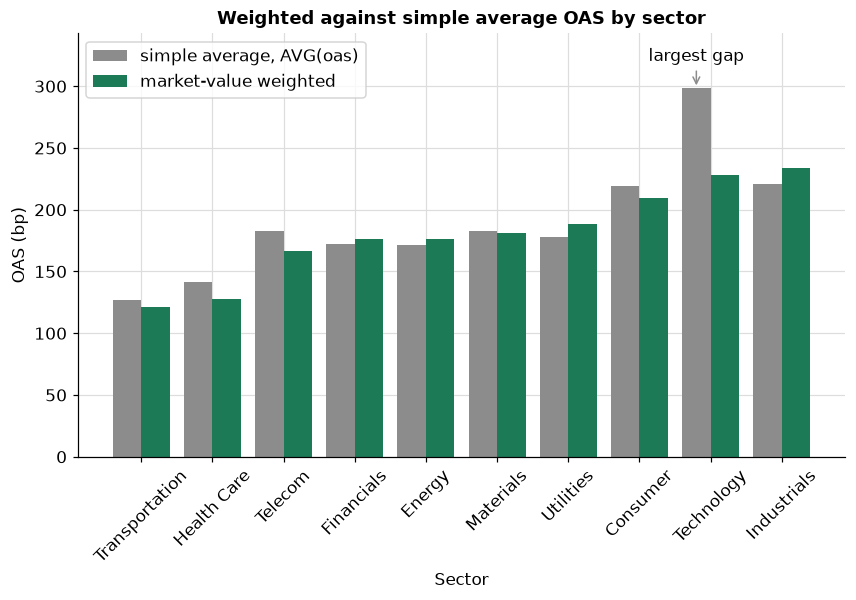

In [39]:
# narrowest weighted OAS on the left; two bars for each sector
both = weighted_sql.sort_values("weighted_oas").reset_index(drop=True)
positions = list(range(len(both)))
fig, ax = plt.subplots()
ax.bar([p - 0.2 for p in positions], both["avg_oas"], width=0.4, color="#8c8c8c", label="simple average, AVG(oas)")
ax.bar([p + 0.2 for p in positions], both["weighted_oas"], width=0.4, color="#1c7a57", label="market-value weighted")
# mark the sector where the two measures are furthest apart
widest = (both["weighted_oas"] - both["avg_oas"]).abs().idxmax()
ax.annotate("largest gap", (widest - 0.2, both.loc[widest, ["avg_oas", "weighted_oas"]].max()), textcoords="offset points",
            xytext=(0, 18), ha="center", arrowprops=dict(arrowstyle="->", color="#8c8c8c"))
ax.set_xticks(positions, both["sector"], rotation=45)
ax.set_axisbelow(True)
ax.margins(y=0.15)
ax.set_xlabel("Sector")
ax.set_ylabel("OAS (bp)")
ax.set_title("Weighted against simple average OAS by sector")
ax.legend(loc="upper left")
plt.show()

* Where the two bars differ, the big positions sit at different spreads from the small ones. Where they match, the weights barely moved the average. The weighted bar is the one a book's spread is usually quoted on.

Q. And the whole book, in one row?

In [40]:
book_sql = md.run_query(db_path, "SELECT COUNT(*) AS bonds, SUM(oas * market_value) / SUM(market_value) AS weighted_oas, "
                                 "AVG(oas) AS avg_oas FROM holdings")
book_weighted = bondmath.weighted_average(holdings["oas"].tolist(), holdings["market_value"].tolist())
assert abs(book_sql.loc[0, "weighted_oas"] - book_weighted) < 1e-9
print(f"{book_sql.loc[0, 'bonds']} bonds: weighted OAS {book_sql.loc[0, 'weighted_oas']:.4f} bp, "
      f"simple average {book_sql.loc[0, 'avg_oas']:.4f} bp, bondmath {book_weighted:.4f} bp")

200 bonds: weighted OAS 180.4610 bp, simple average 185.7500 bp, bondmath 180.4610 bp


* 200 bonds, 180.46 bp weighted and 185.75 bp simple. A query that writes `AVG(oas)` where the question said "weighted" runs, returns a plausible number, and is wrong. Exercise 4 is exactly that.

## Excel Side by Side

Every SQL question today has an Excel answer you already know. Every formula below was typed into Excel by a script (Excel 16.0 build 20430, 2026-10-04) on `holdings.csv` in a sheet: cusip in column A, issuer B, sector C, rating D, oas E, market_value F, and the 200 bonds in rows 2 to 201. Each result equals the SQL and pandas results above.

| Job | SQL | Excel (tested) | Excel returned |
| --- | --- | --- | --- |
| Bonds in a sector | `COUNT(*) ... GROUP BY sector` | `=COUNTIFS($C$2:$C$201,J2)` with the sector in J2 | 17.0 for Energy |
| Market value by sector | `SUM(market_value)` | `=SUMIFS($F$2:$F$201,$C$2:$C$201,J2)` | 38,830,005.0 for Energy |
| Average OAS by sector | `AVG(oas)` | `=AVERAGEIFS($E$2:$E$201,$C$2:$C$201,J2)` | 171.5882353 for Energy |
| Two conditions | `WHERE sector = ? AND oas > ?` with a count | `=COUNTIFS($C$2:$C$201,J2,$E$2:$E$201,">200")` | 3.0 for Energy |
| Weighted OAS by sector | `SUM(oas * market_value) / SUM(market_value)` | `=SUMPRODUCT(($C$2:$C$201=J2)*$E$2:$E$201*$F$2:$F$201)/SUMIFS($F$2:$F$201,$C$2:$C$201,J2)` | 176.3494137 for Energy |
| Rows that pass a filter | `WHERE sector = 'Energy' AND oas > 200` | `=FILTER(A2:A201,(C2:C201="Energy")*(E2:E201>200))` | the 3 cusips, spilled down |
| Top five | `ORDER BY market_value DESC LIMIT 5` | `=TAKE(SORTBY(A2:A201,F2:F201,-1),5)` | the 5 cusips, largest first |
| Keep some groups | `HAVING COUNT(*) >= 20` | `=FILTER(J2:K11,K2:K11>=20)` on the summary block J2:K11 | the 7 sectors with their counts |
| The whole summary | `GROUP BY sector` | a pivot table: sector in Rows; Count of cusip, Sum of market_value, Average of oas in Values | 10 sectors and a Grand Total of 200 bonds, 490,819,215.0 |

**The `IFS` family is `GROUP BY`, one cell at a time.** Type the ten sector names down column J. In K2 type `=COUNTIFS($C$2:$C$201,J2)` and fill it down: one count per sector, as `COUNT(*)` with `GROUP BY sector` gives in one query. `SUMIFS` takes the column to add first, then the criteria pairs; `AVERAGEIFS` the same with an average. Add a second pair, `$E$2:$E$201,">200"`, and `COUNTIFS` counts only the rows that pass both tests, a `WHERE` with `AND`.

**The weighted average** is Course 2's `SUMPRODUCT` with a condition inside: `($C$2:$C$201=J2)` is TRUE or FALSE for each bond, which multiplies as 1 or 0, so only the sector's bonds add to the top line, and `SUMIFS` gives the sector's market value underneath.

**`FILTER`, `SORTBY`, and `TAKE`** are the dynamic array functions. `FILTER` returns the rows where the condition is TRUE, with `*` between two conditions working as AND: that is `WHERE`. `SORTBY(...,F2:F201,-1)` sorts by market value, largest first, and `TAKE(...,5)` keeps the first five: `ORDER BY ... DESC LIMIT 5`. `FILTER` on the summary block keeps the sectors whose count passes: `HAVING`.

**A pivot table** does the whole `GROUP BY` at once: Insert, PivotTable, drag `sector` to Rows, then `cusip`, `market_value`, and `oas` to Values, and set them to Count, Sum, and Average. The SQL and the pandas `groupby` say the same thing in a line that can be rerun, tested, and committed.

Q. Do the SQL results equal what Excel returned?

In [41]:
# what Excel returned for each sector: (COUNTIFS, SUMIFS, AVERAGEIFS, the SUMPRODUCT weighted OAS)
excel_by_sector = {
    "Consumer": [
        26.0,
        56629597.5,
        218.8846153846154,
        209.42688511957022
    ],
    "Energy": [
        17.0,
        38830005.0,
        171.58823529411765,
        176.34941368150737
    ],
    "Financials": [
        26.0,
        68219672.5,
        172.30769230769232,
        176.08312081826543
    ],
    "Health Care": [
        20.0,
        38908187.5,
        141.75,
        128.03327121059033
    ],
    "Industrials": [
        20.0,
        52540745.0,
        220.55,
        233.98383040628755
    ],
    "Materials": [
        26.0,
        71701617.5,
        182.42307692307693,
        180.74204134934612
    ],
    "Technology": [
        12.0,
        30311760.0,
        298.1666666666667,
        228.22711177114098
    ],
    "Telecom": [
        21.0,
        55848270.0,
        182.38095238095238,
        166.8745906990494
    ],
    "Transportation": [
        20.0,
        48822897.5,
        126.5,
        120.94584334123144
    ],
    "Utilities": [
        12.0,
        29006462.5,
        177.91666666666666,
        188.80923432148955
    ]
}
excel_where = ['99145PAA0', '99074WAB8', '99074WAD4']
excel_top5 = ['99080CAE8', '99021VAC2', '99076YAC0', '99129ZAB6', '99144OAF3']

sql_by_sector = by_sector_sql.merge(weighted_sql[["sector", "weighted_oas"]], on="sector", validate="one_to_one")
for row in sql_by_sector.itertuples():
    bonds, market_value, avg_oas, weighted_oas = excel_by_sector[row.sector]
    assert row.bonds == bonds and abs(row.market_value - market_value) < 0.005
    assert abs(row.avg_oas - avg_oas) < 1e-9 and abs(row.weighted_oas - weighted_oas) < 1e-9

where_sql = md.run_query(db_path, "SELECT cusip FROM holdings WHERE sector = ? AND oas > ?", ("Energy", 200))
top_sql = md.run_query(db_path, "SELECT cusip FROM holdings ORDER BY market_value DESC LIMIT ?", (5,))
print(f"{len(sql_by_sector)} sectors: counts, sums to the cent, averages, and weighted OAS equal Excel's")
print(f"FILTER equals WHERE: {sorted(where_sql['cusip']) == sorted(excel_where)}")
print(f"TAKE(SORTBY(...)) equals ORDER BY ... LIMIT, in order: {top_sql['cusip'].tolist() == excel_top5}")

10 sectors: counts, sums to the cent, averages, and weighted OAS equal Excel's
FILTER equals WHERE: True
TAKE(SORTBY(...)) equals ORDER BY ... LIMIT, in order: True


* Every sector agrees, and so do the filter and the top five.

## Save the Day with Git

Today's commit holds the module, the tests, and `queries.sql`, a file of the day's queries. The database file stays out: it is binary, and `load_tables` rebuilds it from the CSV files in one call.

Q. Make the work folder a repository.

In [42]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [43]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course3_11_3b6db0ir and nowhere else


Q. Write the `.gitignore`, the same one as day 1: `.env`, `cache/`, `*.db`, and the folders Python and pytest make.

In [44]:
%%writefile .gitignore
# secrets: your .env holds real keys and is never committed
.env
# downloaded data and databases: rebuilt, never part of the record
cache/
*.db
# folders Python and pytest make
__pycache__/
.pytest_cache/

Writing .gitignore


Q. Which line keeps `course3.db` out?

In [45]:
# check-ignore -v names the file, the line number, and the pattern that matched
!git -C "{work}" check-ignore -v course3.db

.gitignore:5:*.db	course3.db


* `.gitignore:5:*.db`: line 5, the pattern `*.db`, which matches any file ending in `.db`. One pattern covers every database a later day makes.

Q. Write `queries.sql`: the day's queries, with their `?` marks and a comment naming the values. SQL comments start with `--`.

In [46]:
%%writefile queries.sql
-- queries.sql: the day 11 queries on the course's synthetic book. Values go in as ? parameters.

-- four columns of every bond
SELECT cusip, issuer, sector, oas FROM holdings;

-- WHERE: one sector, spreads above a level (parameters: 'Energy', 200)
SELECT cusip, issuer, oas FROM holdings WHERE sector = ? AND oas > ?;

-- ORDER BY and LIMIT: the largest positions by market value (parameter: 5)
SELECT cusip, issuer, market_value FROM holdings ORDER BY market_value DESC LIMIT ?;

-- dates are ISO text, so < compares in date order (parameter: '2030-01-01')
SELECT cusip, issuer, maturity FROM holdings WHERE maturity < ? ORDER BY maturity;

-- GROUP BY: bonds, market value in dollars, and simple average OAS in bp by sector
SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value, AVG(oas) AS avg_oas
FROM holdings GROUP BY sector ORDER BY market_value DESC;

-- HAVING: sectors with at least this many bonds (parameter: 20)
SELECT sector, COUNT(*) AS bonds FROM holdings GROUP BY sector HAVING COUNT(*) >= ? ORDER BY sector;

-- market-value weighted OAS in bp by sector
SELECT sector, SUM(oas * market_value) / SUM(market_value) AS weighted_oas, AVG(oas) AS avg_oas
FROM holdings GROUP BY sector;

Writing queries.sql


Q. What does Git see, ignored files included?

In [47]:
# --ignored lists the ignored files too, marked !!
!git -C "{work}" status --short --ignored

?? .gitignore
?? benchmark.csv
?? bondmath.py
?? course3_excel_reference.csv
?? course3_fred_format_dgs10.json
?? course3_fred_format_dgs2.json
?? course3_synthetic_spreads.csv
?? holdings.csv
?? issuers.csv
?? marketdata.py
?? queries.sql
?? ratings.csv
?? test_marketdata.py
?? trade_blotter.csv
?? treasury_long.csv
?? treasury_par_yields.csv
!! __pycache__/
!! course3.db


* `!! course3.db`: ignored. The data files, `bondmath.py`, and `treasury_long.csv` are copies or rebuilds, so they stay untracked. The four files to commit are `??`.

Q. Commit them.

In [48]:
# choose the four files, commit, then show what went in
!git -C "{work}" add .gitignore marketdata.py test_marketdata.py queries.sql
!git -C "{work}" commit -q -m "Add load_tables, run_query, assert_same_rows, their tests, and queries.sql" -m "The book goes into SQLite; every query is checked against pandas. The database file stays ignored."
!git -C "{work}" log --oneline
!git -C "{work}" show --stat --format=%s HEAD

aa670e0 Add load_tables, run_query, assert_same_rows, their tests, and queries.sql


Add load_tables, run_query, assert_same_rows, their tests, and queries.sql

 .gitignore         |   8 +
 marketdata.py      | 614 +++++++++++++++++++++++++++++++++++++++++++++++++++++
 queries.sql        |  24 +++
 test_marketdata.py | 525 +++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 1171 insertions(+)


* One commit, four text files, and no database. Anyone with the repository and the CSV files can rebuild `course3.db` with `load_tables` and get the same tables.

## Bring It Home

Add today's functions and tests to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code, with the course's `.venv` active.

**Step 1.** Go to your folder and open the two files.

```powershell
Set-Location "$HOME\projects\my_bondmath"
code marketdata.py
code test_marketdata.py
```

Paste the code of today's three `%%writefile -a marketdata.py` cells (sections 11.3 and 11.4), without their first lines, at the end of `marketdata.py`, in order, and the code of the `%%writefile -a test_marketdata.py` cell of section 11.6 at the end of `test_marketdata.py`. Save both.

**Step 2.** Check that `*.db` is in your `.gitignore` (day 1 added it), so a database you make in this folder is never committed.

```powershell
Select-String -Path .gitignore -Pattern "db"
```

**Step 3.** Today's tests read `holdings.csv` and `ratings.csv` from the folder. Copy them in from the course repo's `data` folder, then run the tests.

```powershell
Copy-Item "$HOME\projects\python-fixed-income\data\holdings.csv", "$HOME\projects\python-fixed-income\data\ratings.csv" .
python -m pytest -q test_marketdata.py
```

The last line reads `46 passed`.

**Step 4.** Read the change, then commit.

```powershell
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Add load_tables, run_query, assert_same_rows, their tests"
git log --oneline -3
```

**In Colab**, download `marketdata.py` and `test_marketdata.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Say what SQL is for, and match each SQL clause to the pandas you already know.
* Make a SQLite database in one file with `sqlite3`, and say why `*.db` stays out of Git.
* Load CSV files into tables with `load_tables`, with the row counts checked.
* Write `SELECT`, `WHERE`, `ORDER BY`, and `LIMIT`, and prove each against pandas with `assert_same_rows`.
* Pass every value as a `?` parameter, and show what a pasted value can do.
* Group with `GROUP BY`, `COUNT`, `SUM`, `AVG`, and filter groups with `HAVING`.
* Compute a market-value weighted OAS in SQL and check it against `bondmath.weighted_average`.

Tomorrow, day 12, joins the tables: holdings to issuers and ratings, the bonds in the benchmark that the book does not hold, the join that quietly duplicates rows, and time series in SQL.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell. Every query uses `?` for its values and is checked against pandas with `md.assert_same_rows`.

Q. Run the next cell first. It loads the holdings and the rating scale into a fresh `course3.db`, reads the same two files into pandas, and defines `check`, a small function that marks your answers.

In [49]:
# the two tables the exercises use, in the work folder's database
db_path = work / "course3.db"
print(md.load_tables(db_path, {"holdings": work / "holdings.csv", "ratings": work / "ratings.csv"}))
holdings = pd.read_csv("holdings.csv")
ratings = pd.read_csv("ratings.csv")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

{'holdings': 200, 'ratings': 18}


### Exercise 1

Q. Face held (`par_held`, in dollars) by rating bucket. The bucket is in the `ratings` table, so the query needs one line from tomorrow: `JOIN ratings USING (rating)` after `FROM holdings` adds each bond's `bucket` and `grade`, as `pd.merge(holdings, ratings, on="rating", validate="many_to_one")` does in pandas. Write the query with `SUM(par_held) AS face` and `GROUP BY bucket`, check it against pandas with `md.assert_same_rows`, and store the face of the BBB bucket, as a whole number, in **ex1_bbb_face**.

In [50]:
ex1_bbb_face = ...

In [51]:
check("Exercise 1 BBB face", ex1_bbb_face, 151750000)

Exercise 1 BBB face: not attempted yet


### Exercise 2

Q. The ten widest bonds by OAS, with their issuers: `cusip`, `issuer`, `oas`, widest first. Break any tie on OAS by `cusip`, so the cut is always the same. Check the rows with `md.assert_same_rows` and the order with a second assert, then store the ten cusips, in order, **as a list**, in **ex2_cusips**.

In [52]:
ex2_cusips = ...

In [53]:
check("Exercise 2 the ten widest", ex2_cusips, ['99069RAC4', '99009JAA9', '99038MAE9', '99066OAB6', '99066OAD2', '99038MAH2', '99088KAH5', '99069RAD2', '99036KAA3', '99049XAE2'])

Exercise 2 the ten widest: not attempted yet


### Exercise 3

Q. Add a function to your module. `count_by(db_path, table, column)` returns one row per value of `column` in `table`, with the columns `column` and `row_count`, sorted by the value, counted with SQL through `run_query`. Write the docstring first. A table or column name cannot be a `?` parameter, so check that each name is a plain identifier (`str.isidentifier`) before putting it in the SQL text, and raise `ValueError` if it is not. Then add `test_count_by_matches_pandas`: on the database `build_database(tmp_path)` makes, the counts by sector equal pandas' `value_counts`, and a column name with SQL in it raises `ValueError`. Run pytest, reload the module, and store the number of Energy bonds from `md.count_by(db_path, "holdings", "sector")` in **ex3_energy**.

Write the function in the cell that starts with `%%writefile -a marketdata.py` and the test in the one that starts with `%%writefile -a test_marketdata.py`, and run each of those cells once.

In [54]:
%%writefile -a marketdata.py


# Exercise 3: write count_by(db_path, table, column) below this line

Appending to marketdata.py


In [55]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_count_by_matches_pandas(tmp_path) below this line

Appending to test_marketdata.py


In [56]:
# run pytest, reload the module, then call your function
ex3_energy = ...

In [57]:
check("Exercise 3 Energy bonds", ex3_energy, 17)

Exercise 3 Energy bonds: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for the market-value weighted OAS of the book by grade, and give it the docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Market-value weighted OAS of the book by grade, in basis points.

    Units: OAS in bp; the weights are market values in dollars. Convention: one row per grade, with the
    columns grade, bonds, and oas_bp, where oas_bp is sum(oas x market_value) / sum(market_value) over the
    grade's bonds, the same number bondmath.weighted_average gives.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, and it contains one bug. The `JOIN` line is right; it adds each bond's grade from the `ratings` table, and tomorrow explains it.

In [58]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def weighted_oas_by_grade(db_path):
    """Market-value weighted OAS of the book by grade, in basis points.

    Units: OAS in bp; the weights are market values in dollars. Convention: one row per grade, with the
    columns grade, bonds, and oas_bp, where oas_bp is sum(oas x market_value) / sum(market_value) over the
    grade's bonds, the same number bondmath.weighted_average gives.
    """
    # JOIN ratings USING (rating) adds each bond's grade from the ratings table
    sql = """
    SELECT grade, COUNT(*) AS bonds, AVG(oas) AS oas_bp
    FROM holdings
    JOIN ratings USING (rating)
    GROUP BY grade
    ORDER BY grade
    """
    return md.run_query(db_path, sql)

Q. Before you run the next cell: the numbers it prints will look reasonable. Will they be what the docstring asked for? Read the `SELECT` line.

In [59]:
weighted_oas_by_grade(db_path)

,grade,bonds,oas_bp
0,High Yield,72,339.375000
1,Investment Grade,128,99.335938


Q. Test the function against its docstring before you trust it, with your own `bondmath.weighted_average` as the answer key.

In [60]:
# the test, written from the docstring: each grade against bondmath.weighted_average
result = weighted_oas_by_grade(db_path).set_index("grade")
graded = pd.merge(holdings, ratings, on="rating", validate="many_to_one")
for grade, bonds in graded.groupby("grade"):
    expected = bondmath.weighted_average(bonds["oas"].tolist(), bonds["market_value"].tolist())
    assert result.loc[grade, "bonds"] == len(bonds), f"{grade}: wrong number of bonds"
    assert abs(result.loc[grade, "oas_bp"] - expected) < 1e-9, \
        f"{grade}: {result.loc[grade, 'oas_bp']:.4f} bp from the query, {expected:.4f} bp from bondmath"
print("Both grades equal bondmath.weighted_average")

AssertionError: High Yield: 339.3750 bp from the query, 334.7313 bp from bondmath

Q. Read the test's message, fix the query in the cell that defines the function, and run that cell and the test again until the test passes. Then store the fixed function's Investment Grade `oas_bp` in **ex4_ig** and its High Yield `oas_bp` in **ex4_hy**.

In [61]:
# fix the function above and run the test again, then store the two answers
ex4_ig = ...
ex4_hy = ...

In [62]:
check("Exercise 4 Investment Grade", ex4_ig, 98.78627910957701)
check("Exercise 4 High Yield", ex4_hy, 334.7313192734511)

Exercise 4 Investment Grade: not attempted yet
Exercise 4 High Yield: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```